# exp04: Representasi Fitur

Membandingkan original, clean, penggabungan EAR, HRV absolut, rasio HRV, serta transformasi log HRV. Clean menghapus blink_count, iris_size_delta_std, dan eye_state_other_ratio. Logistic Regression juga membandingkan StandardScaler dengan RobustScaler. Tidak ada tuning parameter model.

Dataset: good_acceptable, window 25 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp04"
WINDOW = "window_25s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_25s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,666
1,Medium,968
2,High,1077


,id,model,scaler,tune,variant,candidate_count
0,xgboost_original,xgboost,NaN,False,original,1
1,xgboost_clean,xgboost,NaN,False,clean,1
2,xgboost_ear,xgboost,NaN,False,ear,1
3,xgboost_absolute,xgboost,NaN,False,absolute,1
4,xgboost_ratio,xgboost,NaN,False,ratio,1
5,xgboost_log,xgboost,NaN,False,log,1
6,logistic_original,logistic,standard,False,original,1
7,logistic_clean,logistic,standard,False,clean,1
8,logistic_ear,logistic,standard,False,ear,1
9,logistic_absolute,logistic,standard,False,absolute,1


2711 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2419,292,3
1,fold_01,Andreas,2566,145,3
2,fold_02,Athaya,2490,221,3
3,fold_03,Fabian,2437,274,3
4,fold_04,Rafi,2413,298,3
5,fold_05,Savitri,2453,258,3
6,fold_06,Shakilla,2617,94,3
7,fold_07,Tio,2465,246,3
8,fold_08,faqih,2446,265,3
9,fold_09,ikhsan,2499,212,3


exp04 / 25s / 1/169 / fold_00 / xgboost_original


exp04 / 25s / 2/169 / fold_00 / xgboost_absolute


exp04 / 25s / 3/169 / fold_00 / xgboost_clean


exp04 / 25s / 4/169 / fold_00 / xgboost_ear


exp04 / 25s / 5/169 / fold_00 / logistic_original


... (163 outputs left out)

exp04 / 25s / 169/169 / fold_12 / xgboost_log


                model  accuracy  balanced_accuracy  macro_f1  windows
    logistic_absolute  0.357433           0.361771  0.355105     2711
       logistic_clean  0.307636           0.323051  0.307433     2711
logistic_clean_robust  0.310218           0.324749  0.310078     2711
         logistic_ear  0.278495           0.295147  0.276535     2711
         logistic_log  0.300627           0.314442  0.300828     2711
    logistic_original  0.307636           0.322860  0.307434     2711
       logistic_ratio  0.333456           0.337342  0.331735     2711
     xgboost_absolute  0.309111           0.314981  0.309043     2711
        xgboost_clean  0.296201           0.300103  0.294951     2711
          xgboost_ear  0.299520           0.302441  0.296780     2711
          xgboost_log  0.296201           0.300103  0.294951     2711
     xgboost_original  0.296938           0.300375  0.295487     2711
        xgboost_ratio  0.282553           0.288202  0.280798     2711


Completed: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_25s_step_5s\full_afc8018c94bb


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_25s_step_5s\full_afc8018c94bb


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
0,logistic_absolute,0.357433,0.361771,0.355105,2711
6,logistic_ratio,0.333456,0.337342,0.331735,2711
2,logistic_clean_robust,0.310218,0.324749,0.310078,2711
7,xgboost_absolute,0.309111,0.314981,0.309043,2711
5,logistic_original,0.307636,0.322860,0.307434,2711
1,logistic_clean,0.307636,0.323051,0.307433,2711
4,logistic_log,0.300627,0.314442,0.300828,2711
9,xgboost_ear,0.299520,0.302441,0.296780,2711
11,xgboost_original,0.296938,0.300375,0.295487,2711
10,xgboost_log,0.296201,0.300103,0.294951,2711


,scope,model,label,precision,recall,f1,support
0,pooled,logistic_absolute,Low,0.269687,0.375375,0.313873,666
1,pooled,logistic_absolute,Medium,0.430851,0.418388,0.424528,968
2,pooled,logistic_absolute,High,0.372038,0.291551,0.326913,1077
42,pooled,logistic_clean,Low,0.243336,0.424925,0.309459,666
43,pooled,logistic_clean,Medium,0.370546,0.322314,0.344751,968
44,pooled,logistic_clean,High,0.338527,0.221913,0.268087,1077
84,pooled,logistic_clean_robust,Low,0.246262,0.420420,0.310593,666
85,pooled,logistic_clean_robust,Medium,0.369718,0.325413,0.346154,968
86,pooled,logistic_clean_robust,High,0.340720,0.228412,0.273485,1077
126,pooled,logistic_ear,Low,0.238570,0.430931,0.307116,666


accuracy                     balanced_accuracy  \
                            min    median       max               min   
model                                                                   
logistic_absolute      0.073333  0.393103  0.542553          0.100000   
logistic_clean         0.026667  0.292683  0.712766          0.035070   
logistic_clean_robust  0.026667  0.296748  0.648936          0.036364   
logistic_ear           0.000000  0.291096  0.507299          0.000000   
logistic_log           0.014151  0.296748  0.797872          0.014876   
logistic_original      0.026667  0.292683  0.712766          0.035070   
logistic_ratio         0.033333  0.369919  0.723404          0.045455   
xgboost_absolute       0.021277  0.291391  0.449664          0.089015   
xgboost_clean          0.021277  0.298013  0.453020          0.089015   
xgboost_ear            0.000000  0.316981  0.486577          0.000000   
xgboost_log            0.021277  0.298013  0.453020          0.089015   
xgboost_original       0.021277  0.291391  0.449664          0.089015   
xgboost_ratio          0.023585  0.295238  0.453020          0.026596   

                                           macro_f1                      
                         median       max       min    median       max  
model                                                                    
logistic_absolute      0.360434  0.523064  0.144737  0.264839  0.508483  
logistic_clean         0.354316  0.492112  0.050231  0.227285  0.467806  
logistic_clean_robust  0.346591  0.523915  0.057920  0.230320  0.502622  
logistic_ear           0.337001  0.466545  0.000000  0.202779  0.469457  
logistic_log           0.343277  0.462577  0.023532  0.218031  0.446429  
logistic_original      0.354316  0.492112  0.049995  0.224923  0.467806  
logistic_ratio         0.372086  0.473521  0.063889  0.313372  0.445820  
xgboost_absolute       0.329138  0.426218  0.122347  0.273333  0.351094  
xgboost_clean          0.289992  0.399392  0.122347  0.256745  0.349227  
xgboost_ear            0.335838  0.400299  0.000000  0.259200  0.354221  
xgboost_log            0.289992  0.399392  0.122347  0.256745  0.349227  
xgboost_original       0.289992  0.418017  0.136236  0.256745  0.349227  
xgboost_ratio          0.303086  0.406567  0.046296  0.256347  0.365369

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

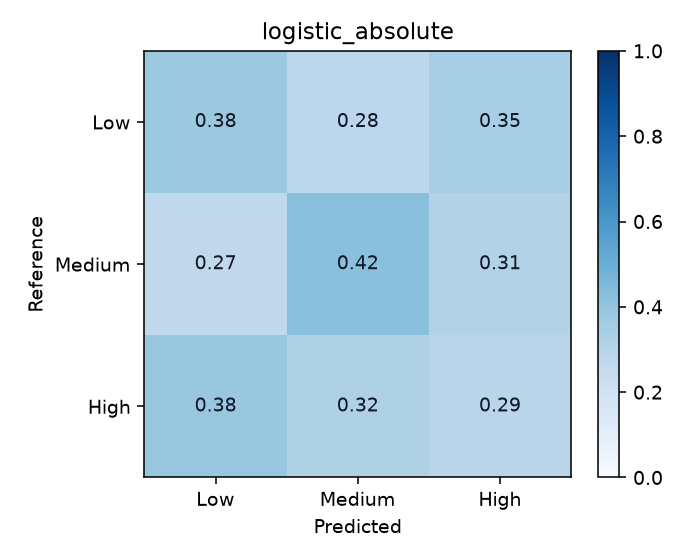

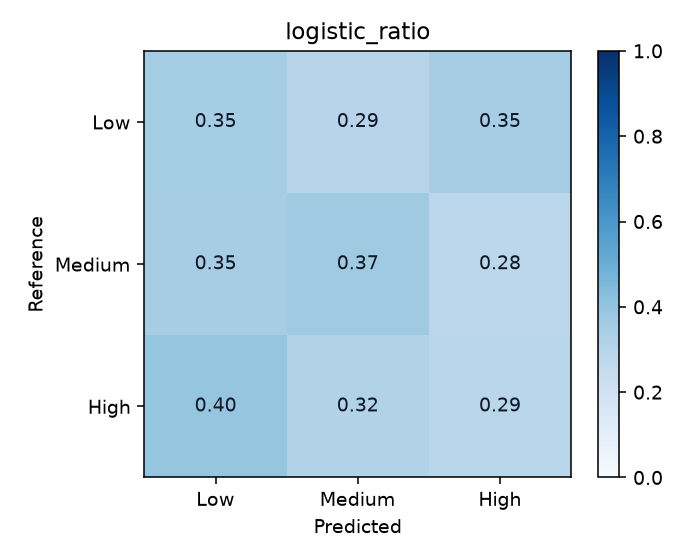

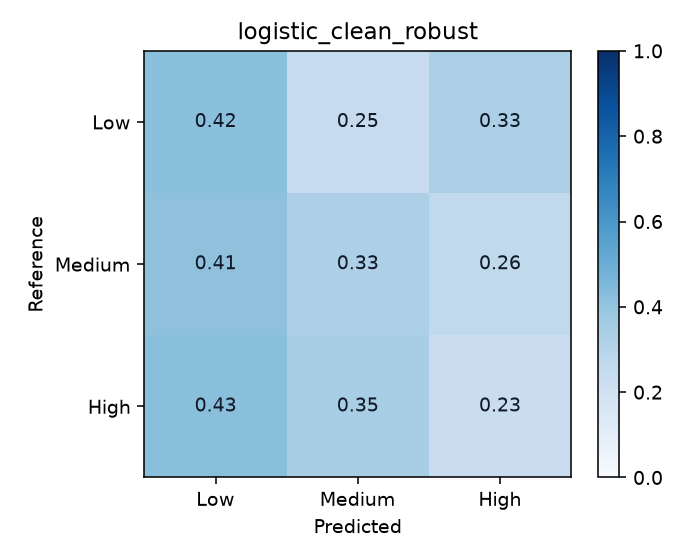

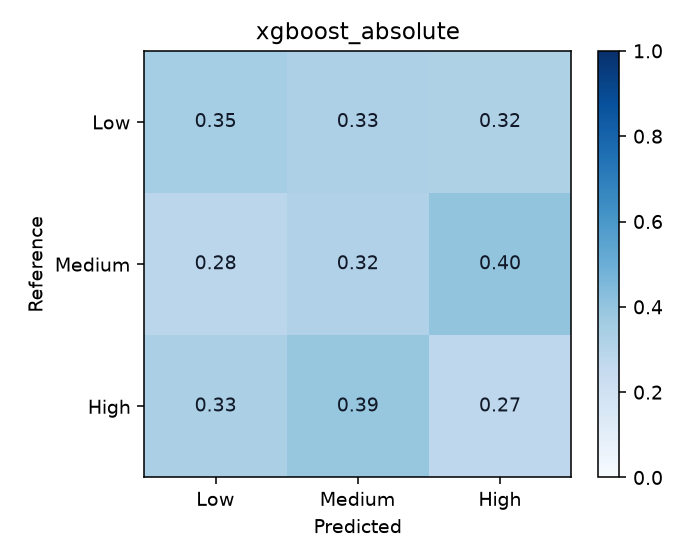

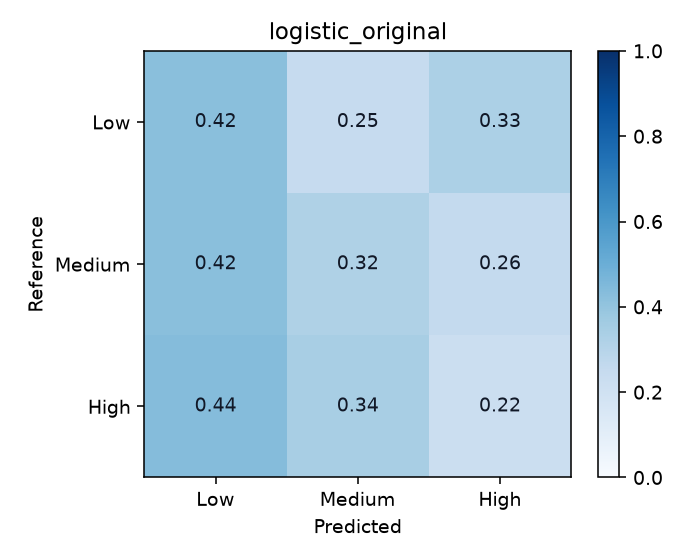

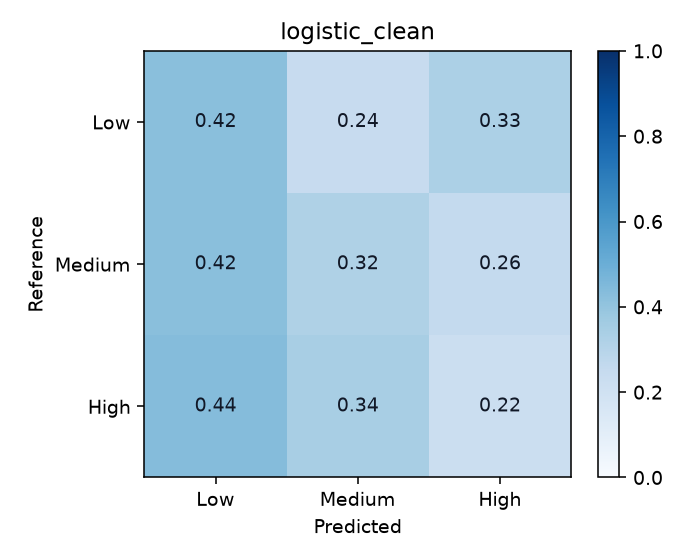

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp04\window_25s_step_5s\full_afc8018c94bb
